# C++: huấn luyện và so sánh BKT, DKT, PAL-Net

Notebook này **tự định nghĩa và tự huấn luyện cả ba mô hình**. Không gọi script training bên ngoài và không nạp checkpoint có sẵn.

Nguyên tắc công bằng:

- cùng dữ liệu và cùng cách chia học viên cho cả ba mô hình;
- cùng ba seed;
- chỉ dùng lịch sử trước lượt đang dự đoán;
- chọn tham số/checkpoint bằng validation log loss;
- test chỉ được đánh giá sau khi đã chọn mô hình;
- DKT và PAL-Net có cùng số epoch tối đa, optimizer, learning rate, weight decay và patience.

Bài tập lấy từ database thật. Người học và kết quả làm bài vẫn là mô phỏng, nên kết quả không chứng minh hiệu quả trên người học thật.


## 1. Cấu hình, đọc và kiểm tra dữ liệu

In [1]:
from pathlib import Path
from collections import defaultdict
import copy, csv, hashlib, json, math, random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display
from torch import nn
from torch.nn.utils.rnn import pad_sequence
from torch.utils.data import DataLoader, Dataset, TensorDataset

LANGUAGE = 'cpp'
SEEDS = (20261013, 20261014, 20261015)
MAX_EPOCHS = 8
PATIENCE = 3
LEARNING_RATE = 0.003
WEIGHT_DECAY = 0.0001
DROPOUT = 0.1

candidate_dirs = (Path.cwd().resolve(), *Path.cwd().resolve().parents)
SERVICE_ROOT = next((p / 'ai-service' for p in candidate_dirs if (p / 'ai-service' / 'data').is_dir()), None)
if SERVICE_ROOT is None:
    SERVICE_ROOT = next((p for p in candidate_dirs if (p / 'data').is_dir() and (p / 'notebooks').is_dir()), None)
if SERVICE_ROOT is None:
    raise RuntimeError('Mở notebook từ thư mục LearnPython hoặc ai-service')

DATA_ROOT = SERVICE_ROOT / 'data' / 'synthetic_history_real_items'
CATALOG_ROOT = SERVICE_ROOT / 'data' / 'real_exercise_catalog'
GRAPH_FILES = {
    'python': SERVICE_ROOT / 'data' / 'pythonSkillGraph.json',
    'javascript': SERVICE_ROOT / 'data' / 'javascriptSkillGraph.json',
    'cpp': SERVICE_ROOT / 'data' / 'cppSkillGraph.json',
}
OUTPUT_ROOT = SERVICE_ROOT / 'outputs' / 'notebook_fair_kt'
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
torch.set_num_threads(1)

FIELDS = (
    'user_id', 'persona_group', 'step_index', 'timestamp', 'language',
    'skill_id', 'item_id', 'item_title', 'lesson_code', 'item_source',
    'difficulty', 'is_correct', 'attempt_index', 'time_taken_seconds',
    'error_type', 'prereq_mastery_proxy',
)

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def load_course(language):
    csv_path = DATA_ROOT / f'{language}_history.csv'
    metadata_path = DATA_ROOT / f'{language}_metadata.json'
    graph_path = GRAPH_FILES[language]
    catalog_path = CATALOG_ROOT / f'{language}_items.json'
    metadata = json.loads(metadata_path.read_text(encoding='utf-8'))
    graph = json.loads(graph_path.read_text(encoding='utf-8'))
    catalog = json.loads(catalog_path.read_text(encoding='utf-8'))
    if metadata['data_origin'] != 'SYNTHETIC_HISTORY_REAL_ITEMS':
        raise ValueError('Sai nguồn dữ liệu')
    if metadata['dataset_sha256'] != sha256(csv_path):
        raise ValueError('Checksum dataset không khớp')
    if metadata['graph_sha256'] != sha256(graph_path):
        raise ValueError('Checksum đồ thị không khớp')
    if metadata['catalog_sha256'] != sha256(catalog_path):
        raise ValueError('Checksum catalog không khớp')

    skills = [str(skill['id']) for skill in graph['skills']]
    skill_index = {skill: index for index, skill in enumerate(skills)}
    adjacency = np.zeros((len(skills), len(skills)), dtype=np.float32)
    for edge in graph['edges']:
        left, right = skill_index[edge['source']], skill_index[edge['target']]
        adjacency[left, right] = adjacency[right, left] = 1.0
    items = {item['item_id']: item for item in catalog['items']}

    grouped = defaultdict(list)
    with csv_path.open(encoding='utf-8', newline='') as handle:
        reader = csv.DictReader(handle)
        if tuple(reader.fieldnames or ()) != FIELDS:
            raise ValueError('Schema dataset không khớp')
        for row in reader:
            item = items.get(row['item_id'])
            if item is None or row['skill_id'] not in item['skill_ids']:
                raise ValueError('Lượt làm không tham chiếu đúng bài tập thật')
            if row['item_title'] != item['item_title'] or row['lesson_code'] != item['lesson_code']:
                raise ValueError('Thông tin bài tập không khớp catalog')
            grouped[row['user_id']].append(row)

    user_names = sorted(grouped)
    sequences, persona_users = {}, defaultdict(list)
    for user_index, user_name in enumerate(user_names):
        rows = sorted(grouped[user_name], key=lambda row: int(row['step_index']))
        if [int(row['step_index']) for row in rows] != list(range(1, len(rows) + 1)):
            raise ValueError(f'Lịch sử không liên tục: {user_name}')
        personas = {row['persona_group'] for row in rows}
        if len(personas) != 1:
            raise ValueError(f'Nhóm hành vi thay đổi: {user_name}')
        sequences[user_index] = [
            {
                'event_id': f"{user_name}:{row['step_index']}",
                'step': int(row['step_index']),
                'skill': skill_index[row['skill_id']],
                'correct': int(row['is_correct']),
                'item_id': row['item_id'],
            }
            for row in rows
        ]
        persona_users[next(iter(personas))].append(user_index)
    return sequences, user_names, dict(persona_users), skills, adjacency, metadata

def split_users(persona_users, seed):
    rng = random.Random(seed)
    result = {'train': [], 'validation': [], 'test': []}
    for persona in sorted(persona_users):
        ids = sorted(persona_users[persona])
        rng.shuffle(ids)
        result['train'].extend(ids[:8])
        result['validation'].extend(ids[8:10])
        result['test'].extend(ids[10:12])
    return {name: tuple(sorted(ids)) for name, ids in result.items()}

sequences, user_names, persona_users, skills, adjacency, metadata = load_course(LANGUAGE)
splits = {seed: split_users(persona_users, seed) for seed in SEEDS}

display(pd.Series({
    'Nguồn bài tập': 'Database thật',
    'Nguồn lịch sử': 'Mô phỏng',
    'Học viên': len(sequences),
    'Lượt nộp': metadata['interactions'],
    'Bài tập thật trong catalog': metadata['catalog_items'],
    'Bài tập thật đã dùng': metadata['items_observed'],
    'Kỹ năng có dữ liệu': metadata['skills_observed'],
    'Có dữ liệu gợi ý': 'Không',
}, name='Kiểm tra dữ liệu').to_frame())
display(pd.DataFrame([
    {'seed': seed, **{part: len(ids) for part, ids in split.items()}}
    for seed, split in splits.items()
]))

,Kiểm tra dữ liệu
Nguồn bài tập,Database thật
Nguồn lịch sử,Mô phỏng
Học viên,60
Lượt nộp,3567
Bài tập thật trong catalog,48
Bài tập thật đã dùng,48
Kỹ năng có dữ liệu,21
Có dữ liệu gợi ý,Không


,seed,train,validation,test
0,20261013,40,10,10
1,20261014,40,10,10
2,20261015,40,10,10


## 2. Metric và cấu trúc kết quả dùng chung

In [2]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True, warn_only=True)

def roc_auc(labels, probabilities):
    labels = np.asarray(labels, dtype=np.int8)
    probabilities = np.asarray(probabilities, dtype=float)
    positives, negatives = int(labels.sum()), int((1 - labels).sum())
    if positives == 0 or negatives == 0:
        return float('nan')
    order = np.argsort(probabilities, kind='mergesort')
    ranks = np.empty(len(probabilities), dtype=float)
    cursor = 0
    while cursor < len(order):
        end = cursor + 1
        while end < len(order) and probabilities[order[end]] == probabilities[order[cursor]]:
            end += 1
        ranks[order[cursor:end]] = (cursor + 1 + end) / 2
        cursor = end
    return float((ranks[labels == 1].sum() - positives * (positives + 1) / 2) / (positives * negatives))

def binary_metrics(labels, probabilities):
    labels = np.asarray(labels, dtype=np.int8)
    probabilities = np.clip(np.asarray(probabilities, dtype=float), 1e-7, 1 - 1e-7)
    predicted = (probabilities >= 0.5).astype(np.int8)
    tp = int(((predicted == 1) & (labels == 1)).sum())
    fp = int(((predicted == 1) & (labels == 0)).sum())
    fn = int(((predicted == 0) & (labels == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    groups = np.array_split(np.argsort(probabilities, kind='mergesort'), 10)
    ece = sum(len(group) / len(labels) * abs(labels[group].mean() - probabilities[group].mean())
              for group in groups if len(group))
    return {
        'events': int(len(labels)),
        'auc_roc': roc_auc(labels, probabilities),
        'accuracy_at_0_5': float((predicted == labels).mean()),
        'f1': float(2 * precision * recall / (precision + recall)) if precision + recall else 0.0,
        'log_loss': float(-(labels * np.log(probabilities) + (1 - labels) * np.log(1 - probabilities)).mean()),
        'brier': float(np.mean((probabilities - labels) ** 2)),
        'ece_equal_count_10': float(ece),
    }

def save_json(path, payload):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(payload, ensure_ascii=False, indent=2) + '\n', encoding='utf-8')

def to_prediction_map(event_ids, labels, probabilities):
    return {event_id: (int(label), float(probability))
            for event_id, label, probability in zip(event_ids, labels, probabilities)}

def parameter_count(model):
    return sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)

runs = {seed: {'split': splits[seed]} for seed in SEEDS}

## 3. Huấn luyện BKT ngay trong notebook

In [3]:
class BKTModel:
    def __init__(self, initial, fallback, learn, guess, slip):
        self.initial = initial
        self.fallback = fallback
        self.learn = learn
        self.guess = guess
        self.slip = slip

    @staticmethod
    def posterior(mastery, correct, guess, slip):
        if correct:
            numerator = mastery * (1 - slip)
            denominator = numerator + (1 - mastery) * guess
        else:
            numerator = mastery * slip
            denominator = numerator + (1 - mastery) * (1 - guess)
        return numerator / max(denominator, 1e-7)

    def predict(self, selected_users):
        ids, labels, probabilities = [], [], []
        for user_id in sorted(selected_users):
            mastery = {}
            for position, event in enumerate(sequences[user_id]):
                skill = event['skill']
                current = mastery.get(skill, self.initial.get(skill, self.fallback))
                probability = current * (1 - self.slip) + (1 - current) * self.guess
                if position > 0:
                    ids.append(event['event_id'])
                    labels.append(event['correct'])
                    probabilities.append(probability)
                posterior = self.posterior(current, event['correct'], self.guess, self.slip)
                mastery[skill] = posterior + (1 - posterior) * self.learn
        return tuple(ids), np.asarray(labels), np.asarray(probabilities)

def train_bkt(train_users, validation_users):
    first_correct, first_total = defaultdict(int), defaultdict(int)
    for user_id in train_users:
        seen = set()
        for event in sequences[user_id]:
            if event['skill'] in seen:
                continue
            seen.add(event['skill'])
            first_correct[event['skill']] += event['correct']
            first_total[event['skill']] += 1
    total_correct, total = sum(first_correct.values()), sum(first_total.values())
    fallback = (total_correct + 1) / (total + 2)
    initial = {skill: (first_correct[skill] + 1) / (count + 2)
               for skill, count in first_total.items()}

    candidates = []
    for learn in (0.05, 0.15, 0.30):
        for guess in (0.05, 0.15, 0.25):
            for slip in (0.05, 0.15, 0.25):
                model = BKTModel(initial, fallback, learn, guess, slip)
                _, labels, probabilities = model.predict(validation_users)
                loss = binary_metrics(labels, probabilities)['log_loss']
                candidates.append((loss, learn, guess, slip, model))
    loss, learn, guess, slip, model = min(candidates, key=lambda row: row[:4])
    return model, {'validation_log_loss': loss, 'learn': learn, 'guess': guess, 'slip': slip}

bkt_rows = []
for seed in SEEDS:
    print(f'Training BKT trực tiếp trong notebook — seed {seed}')
    split = splits[seed]
    model, selection = train_bkt(split['train'], split['validation'])
    validation = to_prediction_map(*model.predict(split['validation']))
    test = to_prediction_map(*model.predict(split['test']))
    runs[seed]['BKT'] = {'validation': validation, 'test': test, 'selection': selection}
    output = OUTPUT_ROOT / LANGUAGE / f'seed_{seed}'
    save_json(output / 'bkt_parameters.json', {
        'trained_in_notebook': True,
        'initial_by_skill': {skills[key]: value for key, value in model.initial.items()},
        'fallback': model.fallback, **selection,
    })
    bkt_rows.append({'seed': seed, **selection})
display(pd.DataFrame(bkt_rows).round(4))

Training BKT trực tiếp trong notebook — seed 20261013
Training BKT trực tiếp trong notebook — seed 20261014
Training BKT trực tiếp trong notebook — seed 20261015


,seed,validation_log_loss,learn,guess,slip
0,20261013,0.7008,0.15,0.25,0.25
1,20261014,0.6885,0.30,0.25,0.25
2,20261015,0.6868,0.30,0.25,0.25


## 4. Huấn luyện DKT ngay trong notebook

In [4]:
class DKTModel(nn.Module):
    def __init__(self, num_skills, embedding_dim=16, hidden_dim=32):
        super().__init__()
        self.embedding = nn.Embedding(num_skills * 2, embedding_dim)
        self.lstm = nn.LSTM(embedding_dim, hidden_dim, batch_first=True)
        self.dropout = nn.Dropout(DROPOUT)
        self.output = nn.Linear(hidden_dim, num_skills)

    def forward(self, tokens):
        hidden, _ = self.lstm(self.embedding(tokens))
        return self.output(self.dropout(hidden))

class DKTSequenceDataset(Dataset):
    def __init__(self, selected_users):
        self.rows = []
        n_skills = len(skills)
        for user_id in sorted(selected_users):
            events = sequences[user_id]
            tokens = [event['skill'] + event['correct'] * n_skills for event in events]
            self.rows.append((
                torch.tensor(tokens[:-1], dtype=torch.long),
                torch.tensor([event['skill'] for event in events[1:]], dtype=torch.long),
                torch.tensor([event['correct'] for event in events[1:]], dtype=torch.float32),
                tuple(event['event_id'] for event in events[1:]),
            ))

    def __len__(self): return len(self.rows)
    def __getitem__(self, index): return self.rows[index]

def collate_dkt(batch):
    tokens, targets, labels, event_ids = zip(*batch)
    lengths = torch.tensor([len(row) for row in tokens])
    mask = torch.arange(int(lengths.max()))[None, :] < lengths[:, None]
    return (pad_sequence(tokens, batch_first=True),
            pad_sequence(targets, batch_first=True),
            pad_sequence(labels, batch_first=True), mask, event_ids)

def evaluate_dkt(model, selected_users):
    loader = DataLoader(DKTSequenceDataset(selected_users), batch_size=8, shuffle=False, collate_fn=collate_dkt)
    model.eval()
    ids, labels_out, probabilities_out = [], [], []
    with torch.no_grad():
        for tokens, targets, labels, mask, event_ids in loader:
            logits = model(tokens).gather(2, targets.unsqueeze(-1)).squeeze(-1)
            probabilities = torch.sigmoid(logits)
            labels_out.extend(labels[mask].numpy().tolist())
            probabilities_out.extend(probabilities[mask].numpy().tolist())
            for row, length in enumerate(mask.sum(dim=1).tolist()):
                ids.extend(event_ids[row][:length])
    return tuple(ids), np.asarray(labels_out), np.asarray(probabilities_out)

def train_dkt(train_users, validation_users, seed):
    set_seed(seed)
    model = DKTModel(len(skills))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.BCEWithLogitsLoss(reduction='none')
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(DKTSequenceDataset(train_users), batch_size=8, shuffle=True,
                        generator=generator, collate_fn=collate_dkt)
    best_loss, best_state, patience_left, log = float('inf'), None, PATIENCE, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        loss_sum, event_count = 0.0, 0
        for tokens, targets, labels, mask, _ in loader:
            optimizer.zero_grad()
            logits = model(tokens).gather(2, targets.unsqueeze(-1)).squeeze(-1)
            losses = criterion(logits, labels)
            loss = losses[mask].mean()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            optimizer.step()
            loss_sum += float(losses[mask].sum())
            event_count += int(mask.sum())
        _, val_labels, val_probabilities = evaluate_dkt(model, validation_users)
        validation_loss = binary_metrics(val_labels, val_probabilities)['log_loss']
        log.append({'epoch': epoch, 'train_log_loss': loss_sum / event_count,
                    'validation_log_loss': validation_loss})
        if validation_loss < best_loss - 1e-6:
            best_loss, best_state, patience_left = validation_loss, copy.deepcopy(model.state_dict()), PATIENCE
        else:
            patience_left -= 1
        if patience_left <= 0: break
    model.load_state_dict(best_state)
    return model, log, best_loss

dkt_rows = []
for seed in SEEDS:
    print(f'Training DKT trực tiếp trong notebook — seed {seed}')
    split = splits[seed]
    model, log, best_loss = train_dkt(split['train'], split['validation'], seed)
    validation = to_prediction_map(*evaluate_dkt(model, split['validation']))
    test = to_prediction_map(*evaluate_dkt(model, split['test']))
    runs[seed]['DKT'] = {'validation': validation, 'test': test, 'train_log': log}
    output = OUTPUT_ROOT / LANGUAGE / f'seed_{seed}' / 'dkt'
    output.mkdir(parents=True, exist_ok=True)
    torch.save({'trained_in_notebook': True, 'state_dict': model.state_dict(), 'seed': seed,
                'best_validation_log_loss': best_loss}, output / 'checkpoint.pt')
    save_json(output / 'train_log.json', {'trained_in_notebook': True, 'epochs': log})
    dkt_rows.append({'seed': seed, 'parameters': parameter_count(model),
                     'epochs': len(log), 'best_validation_log_loss': best_loss})
display(pd.DataFrame(dkt_rows).round(4))

Training DKT trực tiếp trong notebook — seed 20261013


C:\Users\ADMIN\AppData\Local\Temp\ipykernel_57980\1923208818.py:72: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\torch\csrc\autograd\generated\python_variable_methods.cpp:821.)
  loss_sum += float(losses[mask].sum())


Training DKT trực tiếp trong notebook — seed 20261014
Training DKT trực tiếp trong notebook — seed 20261015


,seed,parameters,epochs,best_validation_log_loss
0,20261013,7765,5,0.6922
1,20261014,7765,8,0.6883
2,20261015,7765,8,0.6856


## 5. Huấn luyện PAL-Net ngay trong notebook

In [5]:
def build_history_features():
    event_ids, users, targets, labels, summaries, masteries = [], [], [], [], [], []
    for user_id in sorted(sequences):
        attempts = np.zeros(len(skills), dtype=np.float32)
        corrects = np.zeros(len(skills), dtype=np.float32)
        ema = np.full(len(skills), 0.5, dtype=np.float32)
        total_attempts = total_corrects = 0.0
        for position, event in enumerate(sequences[user_id]):
            target = event['skill']
            if position > 0:
                target_attempts = attempts[target]
                summaries.append(np.asarray([
                    np.log1p(target_attempts),
                    corrects[target] / target_attempts if target_attempts else 0.5,
                    ema[target],
                    np.log1p(total_attempts),
                    total_corrects / total_attempts if total_attempts else 0.5,
                ], dtype=np.float32))
                masteries.append((corrects + 1) / (attempts + 2))
                event_ids.append(event['event_id'])
                users.append(user_id)
                targets.append(target)
                labels.append(event['correct'])
            attempts[target] += 1
            corrects[target] += event['correct']
            ema[target] = 0.7 * ema[target] + 0.3 * event['correct']
            total_attempts += 1
            total_corrects += event['correct']
    return {
        'event_ids': tuple(event_ids), 'users': np.asarray(users),
        'targets': np.asarray(targets), 'labels': np.asarray(labels, dtype=np.float32),
        'summaries': np.stack(summaries), 'masteries': np.stack(masteries).astype(np.float32),
    }

features = build_history_features()

class GraphLayer(nn.Module):
    def __init__(self, dimension):
        super().__init__()
        self.linear = nn.Linear(dimension, dimension)
    def forward(self, values, graph):
        return torch.relu(graph @ self.linear(values))

class PALNet(nn.Module):
    def __init__(self, num_skills, skill_dim=16, history_dim=16, hidden_dim=32):
        super().__init__()
        self.num_skills = num_skills
        self.node_features = nn.Parameter(torch.randn(num_skills, skill_dim) * 0.05)
        self.gcn1, self.gcn2 = GraphLayer(skill_dim), GraphLayer(skill_dim)
        self.history_encoder = nn.Sequential(nn.Linear(5, history_dim), nn.ReLU(),
                                             nn.Linear(history_dim, history_dim), nn.ReLU())
        self.predictor = nn.Sequential(nn.Linear(skill_dim + history_dim + skill_dim, hidden_dim),
                                       nn.ReLU(), nn.Dropout(DROPOUT), nn.Linear(hidden_dim, 1))

    def skill_embeddings(self, graph):
        with_self = graph + torch.eye(self.num_skills)
        degree = with_self.sum(dim=1).clamp_min(1e-7).pow(-0.5)
        normalized = degree[:, None] * with_self * degree[None, :]
        return self.gcn2(self.gcn1(self.node_features, normalized), normalized)

    def forward(self, targets, summaries, masteries, graph):
        embeddings = self.skill_embeddings(graph)
        target_embedding = embeddings[targets]
        history = self.history_encoder(summaries)
        weights = masteries / masteries.sum(dim=1, keepdim=True).clamp_min(1e-7)
        graph_context = weights @ embeddings
        return self.predictor(torch.cat([target_embedding, history, graph_context], dim=1)).squeeze(1)

def pal_dataset(selected_users):
    mask = np.isin(features['users'], np.asarray(selected_users))
    indices = np.flatnonzero(mask)
    return TensorDataset(torch.from_numpy(features['targets'][mask]),
                         torch.from_numpy(features['summaries'][mask]),
                         torch.from_numpy(features['masteries'][mask]),
                         torch.from_numpy(features['labels'][mask])), indices

def evaluate_pal(model, selected_users):
    dataset, indices = pal_dataset(selected_users)
    loader = DataLoader(dataset, batch_size=64, shuffle=False)
    graph = torch.from_numpy(adjacency)
    model.eval()
    probabilities = []
    with torch.no_grad():
        for targets, summaries, masteries, _ in loader:
            probabilities.extend(torch.sigmoid(model(targets, summaries, masteries, graph)).numpy().tolist())
    return (tuple(features['event_ids'][index] for index in indices),
            features['labels'][indices], np.asarray(probabilities))

def train_pal(train_users, validation_users, seed):
    set_seed(seed)
    model = PALNet(len(skills))
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    criterion = nn.BCEWithLogitsLoss()
    dataset, _ = pal_dataset(train_users)
    generator = torch.Generator().manual_seed(seed)
    loader = DataLoader(dataset, batch_size=64, shuffle=True, generator=generator)
    graph = torch.from_numpy(adjacency)
    best_loss, best_state, patience_left, log = float('inf'), None, PATIENCE, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        loss_sum, event_count = 0.0, 0
        for targets, summaries, masteries, labels in loader:
            optimizer.zero_grad()
            logits = model(targets, summaries, masteries, graph)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            loss_sum += float(loss) * len(labels)
            event_count += len(labels)
        _, val_labels, val_probabilities = evaluate_pal(model, validation_users)
        validation_loss = binary_metrics(val_labels, val_probabilities)['log_loss']
        log.append({'epoch': epoch, 'train_log_loss': loss_sum / event_count,
                    'validation_log_loss': validation_loss})
        if validation_loss < best_loss - 1e-6:
            best_loss, best_state, patience_left = validation_loss, copy.deepcopy(model.state_dict()), PATIENCE
        else:
            patience_left -= 1
        if patience_left <= 0: break
    model.load_state_dict(best_state)
    return model, log, best_loss

pal_rows = []
for seed in SEEDS:
    print(f'Training PAL-Net trực tiếp trong notebook — seed {seed}')
    split = splits[seed]
    model, log, best_loss = train_pal(split['train'], split['validation'], seed)
    validation = to_prediction_map(*evaluate_pal(model, split['validation']))
    test = to_prediction_map(*evaluate_pal(model, split['test']))
    runs[seed]['PAL-Net'] = {'validation': validation, 'test': test, 'train_log': log}
    output = OUTPUT_ROOT / LANGUAGE / f'seed_{seed}' / 'palnet'
    output.mkdir(parents=True, exist_ok=True)
    torch.save({'trained_in_notebook': True, 'state_dict': model.state_dict(), 'seed': seed,
                'best_validation_log_loss': best_loss}, output / 'checkpoint.pt')
    save_json(output / 'train_log.json', {'trained_in_notebook': True, 'epochs': log})
    pal_rows.append({'seed': seed, 'parameters': parameter_count(model),
                     'epochs': len(log), 'best_validation_log_loss': best_loss})
display(pd.DataFrame(pal_rows).round(4))

Training PAL-Net trực tiếp trong notebook — seed 20261013
Training PAL-Net trực tiếp trong notebook — seed 20261014
Training PAL-Net trực tiếp trong notebook — seed 20261015


,seed,parameters,epochs,best_validation_log_loss
0,20261013,2849,6,0.6862
1,20261014,2849,8,0.6774
2,20261015,2849,8,0.6732


## 6. So sánh công bằng trên cùng tập test

auc_roc  accuracy_at_0_5      f1  log_loss   brier  \
seed     model                                                         
20261013 BKT       0.5582           0.5846  0.3785    0.6791  0.2430   
         DKT       0.5481           0.5453  0.4504    0.6880  0.2475   
         PAL-Net   0.6115           0.5949  0.4745    0.6677  0.2375   
20261014 BKT       0.5699           0.5588  0.5087    0.6905  0.2484   
         DKT       0.5467           0.5242  0.4009    0.6894  0.2482   
         PAL-Net   0.6210           0.5467  0.3963    0.6774  0.2423   
20261015 BKT       0.5737           0.5678  0.4921    0.6911  0.2486   
         DKT       0.5110           0.5226  0.4196    0.6979  0.2522   
         PAL-Net   0.6175           0.6080  0.5021    0.6691  0.2382   

                  ece_equal_count_10  
seed     model                        
20261013 BKT                  0.0689  
         DKT                  0.0740  
         PAL-Net              0.0411  
20261014 BKT                  0.0476  
         DKT                  0.0715  
         PAL-Net              0.0617  
20261015 BKT                  0.0663  
         DKT                  0.0708  
         PAL-Net              0.0594

auc_roc         accuracy_at_0_5              f1         log_loss  \
           mean     std            mean     std    mean     std     mean   
model                                                                      
BKT      0.5673  0.0081          0.5704  0.0131  0.4598  0.0709   0.6869   
DKT      0.5353  0.0210          0.5307  0.0127  0.4236  0.0250   0.6918   
PAL-Net  0.6167  0.0048          0.5832  0.0323  0.4576  0.0549   0.6714   

                  brier         ece_equal_count_10          
            std    mean     std               mean     std  
model                                                       
BKT      0.0068  0.2467  0.0032             0.0609  0.0116  
DKT      0.0054  0.2493  0.0026             0.0721  0.0017  
PAL-Net  0.0052  0.2393  0.0026             0.0541  0.0113

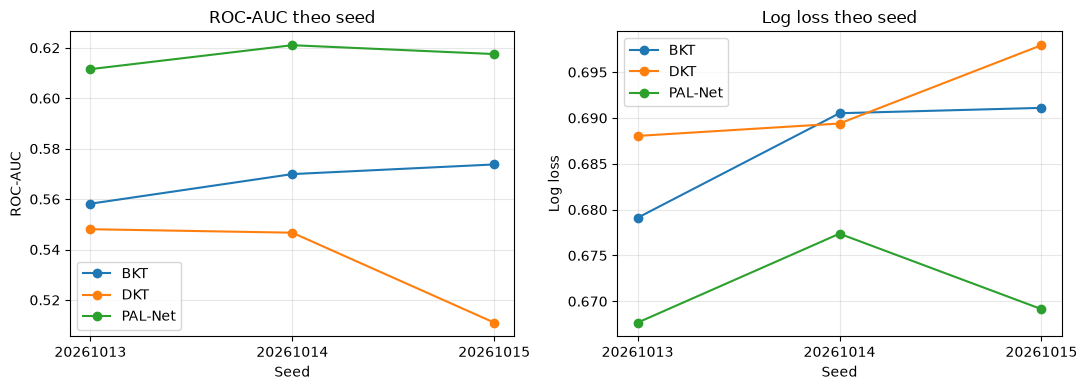

In [6]:
metric_rows = []
for seed in SEEDS:
    keys = set(runs[seed]['BKT']['test'])
    if any(set(runs[seed][model]['test']) != keys for model in ('DKT', 'PAL-Net')):
        raise AssertionError('Ba mô hình không được chấm trên cùng lượt test')
    ordered_keys = sorted(keys)
    labels = np.asarray([runs[seed]['BKT']['test'][key][0] for key in ordered_keys])
    output = OUTPUT_ROOT / LANGUAGE / f'seed_{seed}'
    prediction_rows = []
    report = {
        'language': LANGUAGE, 'seed': seed, 'trained_in_notebook': True,
        'data_origin': metadata['data_origin'],
        'split_user_ids': {part: [user_names[index] for index in ids]
                           for part, ids in splits[seed].items()},
        'selection': 'Mọi lựa chọn dùng validation; test chỉ đánh giá sau khi chọn mô hình.',
        'test': {},
    }
    for model in ('BKT', 'DKT', 'PAL-Net'):
        probabilities = np.asarray([runs[seed][model]['test'][key][1] for key in ordered_keys])
        metrics = binary_metrics(labels, probabilities)
        report['test'][model] = metrics
        metric_rows.append({'seed': seed, 'model': model, **metrics})
    for key, label in zip(ordered_keys, labels):
        prediction_rows.append({
            'event_id': key, 'label': int(label),
            **{model: runs[seed][model]['test'][key][1] for model in ('BKT', 'DKT', 'PAL-Net')},
        })
    with (output / 'test_predictions.csv').open('w', encoding='utf-8', newline='') as handle:
        writer = csv.DictWriter(handle, fieldnames=('event_id', 'label', 'BKT', 'DKT', 'PAL-Net'))
        writer.writeheader(); writer.writerows(prediction_rows)
    save_json(output / 'report.json', report)

results = pd.DataFrame(metric_rows).set_index(['seed', 'model'])
columns = ['auc_roc', 'accuracy_at_0_5', 'f1', 'log_loss', 'brier', 'ece_equal_count_10']
display(results[columns].round(4))
display(results.groupby('model')[columns].agg(['mean', 'std']).round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for model in ('BKT', 'DKT', 'PAL-Net'):
    part = results.xs(model, level='model')
    axes[0].plot(range(len(SEEDS)), part['auc_roc'], marker='o', label=model)
    axes[1].plot(range(len(SEEDS)), part['log_loss'], marker='o', label=model)
for axis, title, ylabel in zip(axes, ('ROC-AUC theo seed', 'Log loss theo seed'), ('ROC-AUC', 'Log loss')):
    axis.set_xticks(range(len(SEEDS)), [str(seed) for seed in SEEDS])
    axis.set(title=title, xlabel='Seed', ylabel=ylabel)
    axis.legend(); axis.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 7. ROC và độ khớp xác suất

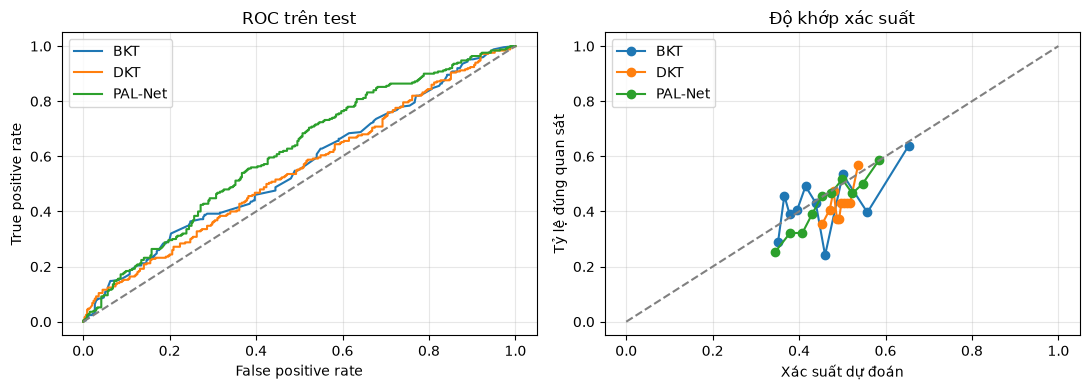

In [7]:
def roc_points(labels, probabilities):
    labels = np.asarray(labels, dtype=np.int8)
    probabilities = np.asarray(probabilities, dtype=float)
    thresholds = np.r_[np.inf, np.unique(probabilities)[::-1]]
    positives, negatives = labels.sum(), len(labels) - labels.sum()
    tpr, fpr = [], []
    for threshold in thresholds:
        predicted = probabilities >= threshold
        tpr.append(np.logical_and(predicted, labels == 1).sum() / positives)
        fpr.append(np.logical_and(predicted, labels == 0).sum() / negatives)
    return np.asarray(fpr), np.asarray(tpr)

def calibration_points(labels, probabilities, bins=10):
    labels, probabilities = np.asarray(labels), np.asarray(probabilities)
    groups = np.array_split(np.argsort(probabilities, kind='mergesort'), bins)
    return (np.asarray([labels[group].mean() for group in groups if len(group)]),
            np.asarray([probabilities[group].mean() for group in groups if len(group)]))

seed = SEEDS[0]
keys = sorted(runs[seed]['BKT']['test'])
labels = np.asarray([runs[seed]['BKT']['test'][key][0] for key in keys])
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for model in ('BKT', 'DKT', 'PAL-Net'):
    probabilities = np.asarray([runs[seed][model]['test'][key][1] for key in keys])
    fpr, tpr = roc_points(labels, probabilities)
    observed, estimated = calibration_points(labels, probabilities)
    axes[0].plot(fpr, tpr, label=model)
    axes[1].plot(estimated, observed, marker='o', label=model)
axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[1].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC trên test')
axes[1].set(xlabel='Xác suất dự đoán', ylabel='Tỷ lệ đúng quan sát', title='Độ khớp xác suất')
for axis in axes: axis.legend(); axis.grid(alpha=.3)
plt.tight_layout(); plt.show()

## Giới hạn khi trình bày

- PAL-Net được dùng đồ thị kỹ năng vì đó là đặc trưng của mô hình; BKT và DKT không dùng đồ thị.
- Công thức sinh đúng/sai không sử dụng mức thành thạo kỹ năng tiên quyết, giảm lợi thế trực tiếp cho PAL-Net; tuy nhiên thứ tự chương trình vẫn đi theo đồ thị khóa học.
- Bài tập là thật nhưng lịch sử học là mô phỏng.
- Không được kết luận PAL-Net luôn tốt hơn, giải quyết hoàn toàn cold-start, ngăn chặn mã độc hoặc chứng minh khoảng 0,70–0,85.
- Checkpoint sinh ra từ notebook chỉ dùng cho nghiên cứu, không phục vụ production.
